# 03 — Model, test evaluation, spatial CV

**Model.** LightGBM with an L1 (absolute-error) objective, so it predicts the conditional *median* travel time, the same quantity as the baselines.

## Features (all known at dispatch)

| feature | type | why it is available at dispatch |
|---|---|---|
| `lat`, `lon` | numeric | incident location, needed to dispatch at all |
| `original_priority_cat` | categorical | priority assigned at call intake, before dispatch (later revisions are excluded) |
| `station_area`, `battalion` | categorical | fixed attributes of the incident location / response area (see the battalion caveat below) |
| `unit_type` | categorical | the unit being dispatched is chosen at dispatch |
| `als_unit` | 0/1 | attribute of the dispatched unit |
| `unit_sequence_in_call_dispatch` | numeric | the order in which this unit is dispatched to the call |
| `hour`, `day_of_week` | numeric | from `received_dttm`, which precedes dispatch |
| `workload_60m` | numeric | distinct calls (raw file, all unit types) received in the 60 min **strictly before** this call's `received_dttm`; same-time and later calls excluded (asserted on a hand-made example) |

**Deliberately not used.**
- `month`: one year of data with a time split, so test months never appear in train.
- `box`: about 2,000 thin levels; `lat`/`lon` carry the same location.
- `neighborhoods_analysis_boundaries`: redundant with location, and when it is assigned is unconfirmed.
- `call_type_group`: forbidden until we confirm when it is assigned.
- `priority`, `final_priority`: can be revised after dispatch.
- `call_final_disposition`: only known when the call ends.
- `response_dttm`, `on_scene_dttm`: after the prediction moment; `on_scene_dttm` is the target itself.

**Protocol.** Tuning uses train → valid only. The chosen configuration is refit on train+valid and evaluated on test **once**.

All logic lives in `src/`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/; make the project root importable.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from src import model, plots
from src.baselines import metric_table

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [2]:
r = model.run()  # ~3 min: tuning, final fit, test evaluation, bootstrap, importance, spatial CV
r["split_counts"]

,rows,calls
split,,
train,66943,66358
valid,8266,8195
test,25252,25027


## Tuning on valid

learning_rate 0.05; the iteration count is the minimum of the valid-MAE curve (capped at 3000).

In [3]:
r["grid"].round({"valid_MAE": 2})

,num_leaves,min_child_samples,best_iter,hit_cap,valid_MAE
0,15,20,1519,False,216.07
1,15,100,988,False,216.43
2,31,20,547,False,216.10
3,31,100,732,False,216.42
4,63,20,214,False,216.20
5,63,100,283,False,216.15


In [4]:
print("chosen:", r["params"], "n_iter:", r["n_iter"])
r["ablation"].round({"valid_MAE": 2})

chosen: {'num_leaves': 15, 'min_child_samples': 20} n_iter: 1519


,features,best_iter,valid_MAE
0,all,1519,216.07
1,without workload_60m,1307,216.89


## Test (the only time test is used)

In [5]:
yt = r["test"]["travel_time_s"]
metric_table(yt, r["test_preds"])

n    MAE   RMSE  MedAE  P90AE  within±120s_%
segment baseline                                                                   
ALL     B0 global median           25252  279.4  403.8  198.0  634.9           31.0
        B1 priority_cat            25252  240.1  353.9  165.0  514.0           38.3
        B2 station x priority_cat  25252  230.6  346.6  151.0  507.5           41.8
        LightGBM L1                25252  214.7  332.5  132.4  490.2           46.5

In [6]:
metric_table(yt, r["test_preds"], r["test"]["unit_type"])

n    MAE   RMSE  MedAE  P90AE  within±120s_%
segment baseline                                                                   
MEDIC   B0 global median           19093  280.3  404.9  197.0  643.0           31.6
        B1 priority_cat            19093  239.3  351.4  164.0  518.0           38.8
        B2 station x priority_cat  19093  230.6  344.0  152.0  513.4           41.9
        LightGBM L1                19093  213.6  325.8  134.0  487.3           46.2
PRIVATE B0 global median            6159  276.5  400.5  201.0  596.2           29.2
        B1 priority_cat             6159  242.8  361.6  168.0  503.2           36.9
        B2 station x priority_cat   6159  230.8  354.7  149.5  484.0           41.3
        LightGBM L1                 6159  218.1  352.6  127.8  502.3           47.7

In [7]:
metric_table(yt, r["test_preds"], r["test"]["priority_group"])

n    MAE   RMSE  MedAE  P90AE  within±120s_%
segment baseline                                                                   
2       B0 global median            8988  375.1  514.6  270.0  818.0           24.6
        B1 priority_cat             8988  308.4  418.6  247.0  608.0           25.2
        B2 station x priority_cat   8988  301.0  412.5  236.0  606.3           26.9
        LightGBM L1                 8988  288.2  401.0  220.2  594.4           28.9
3       B0 global median           11329  193.4  270.9  163.0  335.0           36.9
        B1 priority_cat            11329  170.7  274.3  116.0  338.0           51.5
        B2 station x priority_cat  11329  157.9  263.3  102.0  318.0           57.3
        LightGBM L1                11329  141.7  250.1   86.2  286.2           64.1
other   B0 global median            4935  302.5  428.4  213.0  690.6           29.1
        B1 priority_cat             4935  275.2  386.2  203.0  575.6           31.8
        B2 station x priority_cat   4935  269.3  381.8  194.0  586.0           33.2
        LightGBM L1                 4935  248.4  359.7  169.0  547.5           38.3

### Paired bootstrap: B2 − model on test

1,000 resamples (seed 0). Positive values mean the model is better than B2.

**Headline: resampling calendar days** of `received_dttm` (92 clusters). Calls on the same day share weather, traffic and system load, so the day is the more honest independent unit. The call-level resample is shown for comparison.

In [8]:
print(f"day-level ({r['n_test_days']} days):")
r["bootstrap_day"].round(1)

day-level (92 days):


,estimate,ci_2.5%,ci_97.5%
MAE(B2) - MAE(model),15.9,14.8,17.0
RMSE(B2) - RMSE(model),14.1,12.7,15.5


In [9]:
print(f"call-level ({r['test']['call_number'].nunique():,} calls):")
r["bootstrap"].round(1)

call-level (25,027 calls):


,estimate,ci_2.5%,ci_97.5%
MAE(B2) - MAE(model),15.9,14.8,17.1
RMSE(B2) - RMSE(model),14.1,12.9,15.4


### Sensitivity: test without R7 (no 60-minute cap)

In [10]:
model.r7_comparison(r)

,MAE_R7,MAE_noR7,RMSE_R7,RMSE_noR7,RMSE_change
model,,,,,
B0 global median,279.4,280.1,403.8,408.4,4.6
B1 priority_cat,240.1,240.8,353.9,358.8,4.9
B2 station x priority_cat,230.6,231.3,346.6,351.6,5.0
LightGBM L1,214.7,215.4,332.5,337.8,5.2


### Permutation importance (test, MAE scoring, 5 repeats)

,MAE_increase_s,std_s
original_priority_cat,77.16,0.27
unit_sequence_in_call_dispatch,23.80,0.32
station_area,11.13,0.47
workload_60m,3.61,0.20
lat,3.54,0.08
lon,2.70,0.15
hour,2.63,0.17
unit_type,1.63,0.25
als_unit,1.41,0.20
battalion,1.08,0.10


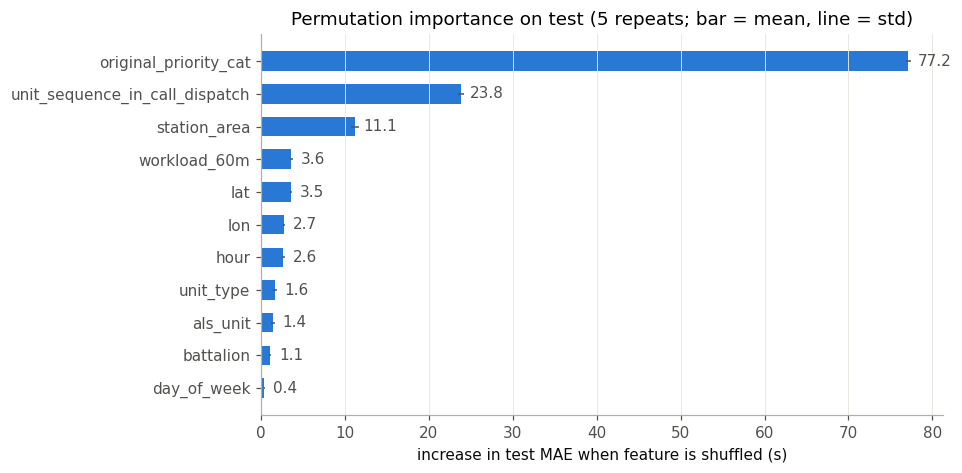

In [11]:
plots.permutation_importance_bar(r["importance"])
r["importance"]

## Spatial CV: leave-one-spatial-block-out (train+valid)

KMeans on incident `lat`/`lon` (one point per call, with lon scaled by cos(latitude) so blocks are not stretched east–west) gives 10 contiguous blocks. Each fold holds out one block, so its locations are genuinely absent from training. The model and B2 use the same configuration as above, and `n_iter` is the one chosen on valid.

In [12]:
r["block_rows"]  # rows per block and block centroids

,rows,centroid_lat,centroid_lon
block,,,
0,24402,37.7810,-122.4101
1,4581,37.7230,-122.4292
2,3617,37.7638,-122.4533
3,5388,37.7319,-122.3941
4,10104,37.7871,-122.4304
5,7034,37.7968,-122.4023
6,3103,37.7487,-122.4913
7,3100,37.7794,-122.4838
8,10380,37.7607,-122.4188


In [13]:
r["block_table"]

,held_out,rows,MAE_LightGBM L1,MAE_B2,B2_minus_model,B2_cell_share_%
0,0,24402,213.6,225.9,12.3,66.5
1,8,10380,205.5,209.0,3.6,36.0
2,4,10104,209.9,225.7,15.8,47.9
3,5,7034,253.8,275.8,22.0,74.0
4,3,5388,217.5,245.1,27.6,40.4
5,1,4581,227.7,244.4,16.7,57.6
6,2,3617,216.0,229.4,13.3,60.4
7,9,3500,219.9,239.9,19.9,74.1
8,6,3103,239.6,263.5,24.0,26.4
9,7,3100,229.8,250.7,20.9,37.1


In [14]:
r["block_summary"]

,MAE_LightGBM L1,MAE_B2,B2_minus_model
mean,223.3,240.9,17.6
std,14.7,19.6,6.9
min,205.5,209.0,3.6
max,253.8,275.8,27.6


## Stability across battalions (not a clean spatial hold-out)

Leave-one-battalion-out, kept for reference. **Caveat:** in this data `station_area` is *not* nested in `battalion`; most station areas occur under several battalions. A held-out battalion therefore shares station areas and locations with the training folds. (Battalion is constant within a call, so it is an incident-level field, but its boundaries do not follow station areas.)

In [15]:
print(r["nesting"])
r["spatial_table"]

{'station_areas': 44, 'station_areas_in_>1_battalion': 36, 'rows_outside_modal_battalion_%': 24.4}


,held_out,rows,MAE_LightGBM L1,MAE_B2,B2_minus_model,B2_cell_share_%
0,B02,15536,196.6,210.0,13.3,93.7
1,B03,14380,233.7,247.3,13.6,61.9
2,B04,8071,220.2,233.4,13.2,65.3
3,B01,6535,227.5,243.6,16.1,66.9
4,B10,6146,233.6,243.4,9.7,35.6
5,B08,5892,232.1,257.0,24.9,27.9
6,B09,5857,222.4,243.0,20.6,42.4
7,B06,4746,198.8,208.9,10.1,56.9
8,B05,4555,201.3,211.8,10.5,76.6
9,B07,3491,225.5,245.7,20.2,16.5


In [16]:
r["spatial_summary"]

,MAE_LightGBM L1,MAE_B2,B2_minus_model
mean,219.2,234.4,15.2
std,14.7,17.6,5.1
min,196.6,208.9,9.7
max,233.7,257.0,24.9
